# MRNet Experiment 2 — Attention Pooling

.


In [ ]:
!pip install -q redivis

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score,
)
from google.colab import drive

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:

EPOCHS        = 3
LEARNING_RATE = 1e-3
LABEL_COLUMNS = ["abnormal", "acl", "meniscus"]
VIEW          = "sagittal"

drive.mount("/content/drive")
DRIVE_ROOT  = Path("/content/drive/MyDrive/mrnet")
CACHE_ROOT  = DRIVE_ROOT / "cache"
RESULTS_DIR = DRIVE_ROOT / "results" / "exp2_controlled_attention"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results will be saved to:", RESULTS_DIR)


Mounted at /content/drive
Results will be saved to: /content/drive/MyDrive/mrnet/results/exp2_controlled_attention


## 1 · Load exam tables

In [ ]:
train_exams = pd.read_parquet(DRIVE_ROOT / "train_exams.parquet")
valid_exams = pd.read_parquet(DRIVE_ROOT / "valid_exams.parquet")

print(f"Train: {len(train_exams)} exams | Valid: {len(valid_exams)} exams")
print("\nPositive rates (train):")
print(train_exams[LABEL_COLUMNS].mean().round(3))

Train: 1129 exams | Valid: 119 exams

Positive rates (train):
abnormal    0.808
acl         0.184
meniscus    0.352
dtype: float32


## 2 · Dataset

In [ ]:
class SingleViewDataset(Dataset):

    def __init__(self, exams: pd.DataFrame, cache_root: Path, view: str):
        self.exams      = exams.reset_index(drop=True)
        self.cache_root = cache_root
        self.view       = view

    def __len__(self):
        return len(self.exams)

    def __getitem__(self, idx):
        row     = self.exams.iloc[idx]
        exam_id = row["exam_id"]
        labels  = row[LABEL_COLUMNS].to_numpy(dtype=np.float32)
        vol     = np.load(self.cache_root / self.view / f"{exam_id}.npy")
        volume  = torch.from_numpy(vol.astype(np.float32) / 255.0)  # (S, H, W)
        return volume, torch.tensor(labels), exam_id


train_ds     = SingleViewDataset(train_exams, CACHE_ROOT / "train", VIEW)
valid_ds     = SingleViewDataset(valid_exams, CACHE_ROOT / "valid", VIEW)
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True,  num_workers=0, pin_memory=(torch.cuda.is_available()))
valid_loader = DataLoader(valid_ds, batch_size=1, shuffle=False, num_workers=0, pin_memory=(torch.cuda.is_available()))

vol, tgt, eid = train_ds[0]
print(f"Example: exam={eid}, volume={tuple(vol.shape)}, labels={tgt.tolist()}")

Example: exam=0060, volume=(18, 256, 256), labels=[0.0, 0.0, 0.0]


## 3 · Model

In [ ]:
def prepare_slices(volume: torch.Tensor, size: int = 224) -> torch.Tensor:
    """(S, H, W) → (S, 3, size, size) in [0,1]"""
    x = volume.unsqueeze(1)
    x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    return x.repeat(1, 3, 1, 1)


class AttentionMIL(nn.Module):
\
    def __init__(self, feature_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.V = nn.Sequential(nn.Linear(feature_dim, hidden_dim), nn.Tanh())
        self.U = nn.Sequential(nn.Linear(feature_dim, hidden_dim), nn.Sigmoid())
        self.w = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, h: torch.Tensor):
        gate  = self.V(h) * self.U(h)
        a     = torch.softmax(self.w(gate).squeeze(-1), dim=0)
        return (a.unsqueeze(1) * h).sum(0), a


class ResNet18AttentionModel(nn.Module):

    def __init__(self):
        super().__init__()
        from torchvision.models import resnet18, ResNet18_Weights
        backbone   = resnet18(weights=ResNet18_Weights.DEFAULT)
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])  # (N,512,1,1)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1,3,1,1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1,3,1,1))
        for p in self.encoder.parameters():
            p.requires_grad = False
        self.encoder.eval()

        self.attention  = AttentionMIL(512, hidden_dim=128)
        self.classifier = nn.Linear(512, 3)

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()   \
        return self

    @torch.no_grad()
    def _extract_features(self, volume: torch.Tensor) -> torch.Tensor:
        """volume: (S, H, W) → features (S, 512)"""
        slices = prepare_slices(volume)
        slices = (slices - self.mean) / self.std
        feats  = []
        for i in range(0, slices.shape[0], 8):
            feats.append(self.encoder(slices[i:i+8]).flatten(1))
        return torch.cat(feats, dim=0)

    def forward(self, volume: torch.Tensor):
        h          = self._extract_features(volume)   # (S, 512)
        z, att     = self.attention(h)                # (512,), (S,)
        logits     = self.classifier(z)               # (3,)
        return logits, att


model     = ResNet18AttentionModel().to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {trainable:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 121MB/s]


Trainable params: 132,995


## 4 · Training

In [ ]:

y_train = train_exams[LABEL_COLUMNS].to_numpy(dtype=np.float32)
pos = y_train.sum(axis=0)
neg = len(y_train) - pos
pos_weight = torch.tensor(neg / np.maximum(pos, 1.0), dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)

history = []
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for volume, target, _exam_id in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"):
        volume = volume.squeeze(0).to(device)
        target = target.squeeze(0).to(device)

        optimizer.zero_grad()
        logits, _attention_weights = model(volume)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    mean_loss = total_loss / max(len(train_loader), 1)
    history.append(mean_loss)
    print(f"Epoch {epoch + 1}/{EPOCHS} — training loss: {mean_loss:.4f}")

print("Training complete.")


Epoch 1/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 1/3 — training loss: 0.7620


Epoch 2/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 2/3 — training loss: 0.7028


Epoch 3/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 3/3 — training loss: 0.6589
Training complete.


## 5 · Evaluation

In [ ]:
model.eval()
all_targets, all_probs, all_ids = [], [], []

with torch.no_grad():
    for volume, target, exam_id in tqdm(valid_loader, desc="Validation"):
        volume = volume.squeeze(0).to(device)
        with autocast():
            logits, _ = model(volume)
        probs = torch.sigmoid(logits).float().cpu().numpy()
        all_targets.append(target.squeeze(0).numpy())
        all_probs.append(probs)
        all_ids.append(exam_id[0])

y_true = np.asarray(all_targets)
y_prob = np.asarray(all_probs)
y_pred = (y_prob >= 0.5).astype(int)

rows = []
for j, label in enumerate(LABEL_COLUMNS):
    auc = roc_auc_score(y_true[:, j], y_prob[:, j]) \
          if len(np.unique(y_true[:, j])) == 2 else float("nan")
    ap  = average_precision_score(y_true[:, j], y_prob[:, j]) \
          if y_true[:, j].sum() > 0 else float("nan")
    rows.append({
        "label":         label,
        "ROC_AUC":       round(auc, 3),
        "Avg_Precision": round(ap,  3),
        "Accuracy@0.5":  round(accuracy_score(y_true[:, j], y_pred[:, j]), 3),
        "Precision@0.5": round(precision_score(y_true[:, j], y_pred[:, j], zero_division=0), 3),
        "Recall@0.5":    round(recall_score(y_true[:, j], y_pred[:, j],    zero_division=0), 3),
        "F1@0.5":        round(f1_score(y_true[:, j], y_pred[:, j],        zero_division=0), 3),
    })

metrics_df = pd.DataFrame(rows)
metrics_df.insert(0, "experiment", 2)
metrics_df.insert(1, "encoder",    "resnet18")
display(metrics_df)

Validation:   0%|          | 0/119 [00:00<?, ?it/s]

/tmp/ipykernel_850/1670612861.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_850/1670612861.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_850/1670612861.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_850/1670612861.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_850/1670612861.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_850/1670612861.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please us

,experiment,encoder,label,ROC_AUC,Avg_Precision,Accuracy@0.5,Precision@0.5,Recall@0.5,F1@0.5
0,2,resnet18,abnormal,0.886,0.967,0.857,0.882,0.947,0.914
1,2,resnet18,acl,0.863,0.791,0.580,0.520,0.981,0.679
2,2,resnet18,meniscus,0.745,0.679,0.597,0.523,0.885,0.657


## 6 · Plots

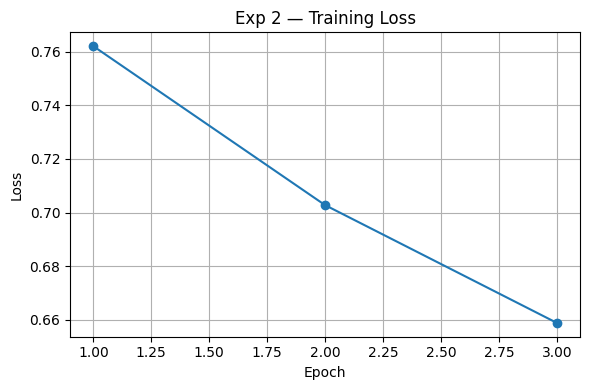

In [ ]:
# Training loss
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(history)+1), history, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Exp 2 — Training Loss")
plt.grid(True); plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=120)
plt.show()

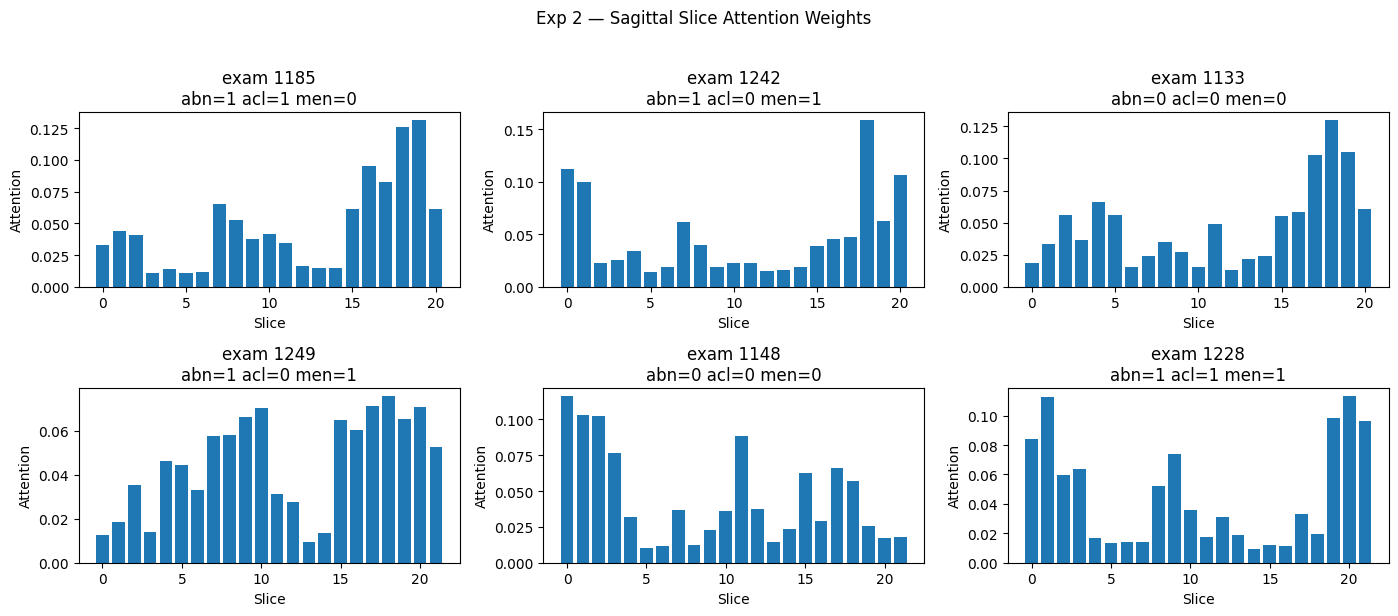

In [ ]:
# Attention weights for a few validation exams
model.eval()
fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for ax, idx in zip(axes.flatten(), range(6)):
    vol, lbl, eid = valid_ds[idx]
    with torch.no_grad():
        _, att = model(vol.to(device))
    att = att.float().cpu().numpy()
    ax.bar(range(len(att)), att)
    ax.set_title(f"exam {eid}\nabn={int(lbl[0])} acl={int(lbl[1])} men={int(lbl[2])}")
    ax.set_xlabel("Slice"); ax.set_ylabel("Attention")

plt.suptitle("Exp 2 — Sagittal Slice Attention Weights", y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "attention_weights.png", dpi=120, bbox_inches="tight")
plt.show()

## 7 · Save checkpoint & results

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "label_columns":    LABEL_COLUMNS,
    "experiment":       2,
    "encoder":          "resnet18",
    "epochs":           EPOCHS,
    "train_history":    history,
    "seed":             SEED,
}, RESULTS_DIR / "checkpoint.pt")
print("Checkpoint saved.")

metrics_df.to_csv(RESULTS_DIR / "metrics.csv", index=False)

# Append to shared results table
shared_csv = DRIVE_ROOT / "results" / "all_results.csv"
if shared_csv.exists():
    existing = pd.read_csv(shared_csv)
    existing = existing[~(existing["experiment"] == 2)]
    combined = pd.concat([existing, metrics_df], ignore_index=True)
else:
    combined = metrics_df
combined.to_csv(shared_csv, index=False)
print("Results saved to:", shared_csv)

Checkpoint saved.
Results saved to: /content/drive/MyDrive/mrnet/results/all_results.csv


In [ ]:
from sklearn.metrics import roc_auc_score, f1_score
import numpy as np

for j, label in enumerate(LABEL_COLUMNS):
    y = y_true[:, j].astype(int)
    p = y_prob[:, j]

    print(f"\n{label}")
    print("Probability range:", round(p.min(), 4), "to", round(p.max(), 4))
    print("Probability percentiles:",
          np.round(np.percentile(p, [0, 25, 50, 75, 100]), 4))

    thresholds = np.arange(0.05, 0.96, 0.05)
    scores = [
        f1_score(y, p >= t, zero_division=0)
        for t in thresholds
    ]
    best = int(np.argmax(scores))

    print("Best validation F1:", round(scores[best], 3))
    print("Threshold giving that F1:", round(thresholds[best], 2))


abnormal
Probability range: 0.085 to 0.9995
Probability percentiles: [0.085  0.7002 0.9204 0.9734 0.9995]
Best validation F1: 0.919
Threshold giving that F1: 0.45

acl
Probability range: 0.2781 to 0.9722
Probability percentiles: [0.2781 0.5613 0.7222 0.8833 0.9722]
Best validation F1: 0.8
Threshold giving that F1: 0.7

meniscus
Probability range: 0.1589 to 0.9692
Probability percentiles: [0.1589 0.4796 0.6909 0.792  0.9692]
Best validation F1: 0.7
Threshold giving that F1: 0.65
